# Demographic Data for groups G+H

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --- Group variable: change this to switch between groups ---
group_csv   = "group_gh_ssids.csv"
group_label = "Group G+H"
group_short = "group_gh"

# --- Paths ---
enrollment_dir = "../1095 Data/Enrollment"

os.makedirs("plots", exist_ok=True)

# --- Load group SSIDs ---
group_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"{group_label}: {len(group_ssids):,} students")

# --- Load 2021-22 enrollment, filter to group, deduplicate ---
enrollment = pd.read_csv(os.path.join(enrollment_dir, "CEnrollment_21-22.csv"), low_memory=False)
enrollment_group = (
    enrollment[enrollment["SSID"].isin(group_ssids)]
    .drop_duplicates(subset="SSID", keep="first")
)
print(f"Enrollment records for {group_label}: {len(enrollment_group):,}")

Group G+H: 12,918 students
Enrollment records for Group G+H: 12,918


In [3]:
# --- CALPADS language code lookup ---
language_code_map = {
    "00": "English", "01": "Spanish", "02": "Vietnamese", "03": "Cantonese",
    "04": "Korean", "05": "Filipino (Tagalog)", "06": "Portuguese", "07": "Mandarin",
    "08": "Japanese", "09": "Khmer (Cambodian)", "10": "Lao", "11": "Arabic",
    "12": "Armenian", "13": "Burmese", "15": "Dutch", "16": "Farsi (Persian)",
    "17": "French", "18": "German", "19": "Greek", "20": "Chamorro", "21": "Hebrew",
    "22": "Hindi", "23": "Hmong", "24": "Hungarian", "25": "Ilocano", "26": "Indonesian",
    "27": "Italian", "28": "Punjabi", "29": "Russian", "30": "Samoan", "32": "Thai",
    "33": "Turkish", "34": "Tongan", "35": "Urdu", "36": "Cebuano", "37": "Sign Language",
    "38": "Ukrainian", "40": "Pashto", "41": "Polish", "42": "Assyrian", "43": "Gujarati",
    "44": "Mien (Yao)", "54": "Chaldean", "60": "Somali", "61": "Bengali", "62": "Telugu",
    "63": "Tamil", "66": "Amharic", "73": "Haitian Creole", "76": "Nepali", "77": "Swahili",
    "99": "Other non-English", "UU": "Unknown",
}

# --- Grade label lookup ---
grade_order  = ["KN", "01", "02", "03", "04", "05", "06", "07", "08", "09", "10", "11", "12", "PS"]
grade_labels = {
    "KN": "Kindergarten", "01": "Grade 1", "02": "Grade 2", "03": "Grade 3",
    "04": "Grade 4", "05": "Grade 5", "06": "Grade 6", "07": "Grade 7",
    "08": "Grade 8", "09": "Grade 9", "10": "Grade 10", "11": "Grade 11",
    "12": "Grade 12", "PS": "Preschool",
}

# --- Race/ethnicity label lookup ---
race_labels = {
    "H": "Hispanic/Latino", "D": "Asian", "F": "Filipino", "I": "Amer. Indian/AK Native",
    "P": "Pacific Islander", "B": "Black/African Amer.", "W": "White", "T": "Two or More Races",
    "N": "Not Reported",
}


def make_pie_and_table(series, title, filename_suffix,
                       label_map=None, keep_order=None,
                       min_pct=0.0, sort_by_count=True):
    """
    Build a pie chart (saved to plots/) and print a data table for a categorical series.
    - label_map: optional dict mapping raw code -> readable label
    - keep_order: optional list forcing category order (e.g. grade order)
    - min_pct: categories below this fraction are grouped into "Other" (0 = keep all)
    - sort_by_count: sort slices by count descending (ignored if keep_order given)
    """
    counts = series.dropna().astype(str).str.strip().value_counts()
    total = counts.sum()

    # Group small categories into "Other"
    if min_pct > 0:
        keep = counts[counts / total >= min_pct]
        other_sum = counts[counts / total < min_pct].sum()
        if other_sum > 0:
            keep["Other"] = other_sum
        counts = keep

    # Order the categories
    if keep_order is not None:
        ordered = [c for c in keep_order if c in counts.index]
        ordered += [c for c in counts.index if c not in ordered]  # any extras at the end
        counts = counts.reindex(ordered)
    elif sort_by_count:
        counts = counts.sort_values(ascending=False)

    # Build display labels
    def disp(code):
        if code == "Other":
            return "Other"
        if label_map and code in label_map:
            return f"{label_map[code]} ({code})"
        return str(code)

    pie_labels = [disp(c) for c in counts.index]

    # --- Pie chart ---
    n = len(counts)
    fig, ax = plt.subplots(figsize=(11, 11) if n > 12 else (10, 10))

    # Choose a colormap with enough distinct colors
    if n <= 20:
        pie_colors = plt.cm.tab20.colors[:n]
    else:
        pie_colors = [plt.cm.tab20(i % 20) for i in range(n)]

    wedges, texts, autotexts = ax.pie(
        counts.values,
        labels=pie_labels,
        autopct=lambda pct: f"{pct:.1f}%\n({int(round(pct/100*total)):,})",
        startangle=90,
        colors=pie_colors,
        wedgeprops={"edgecolor": "white", "linewidth": 1},
        textprops={"fontsize": 8},
        pctdistance=0.78,
    )
    for autotext in autotexts:
        autotext.set_fontsize(7)
        autotext.set_color("black")

    ax.set_title(f"{group_label} — {title}\n(n={total:,} students)",
                 fontsize=14, fontweight="bold")

    plt.tight_layout()
    out_path = f"plots/{group_short}_pie_{filename_suffix}.png"
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")

    # --- Data table ---
    print(f"\n{title} — Distribution:")
    print(f"{'Category':<35} {'Count':>10} {'Percent':>9}")
    print("-" * 56)
    for code, count in counts.items():
        pct = count / total * 100
        print(f"{disp(code):<35} {count:>10,} {pct:>8.1f}%")
    print("-" * 56)
    print(f"{'Total':<35} {total:>10,} {100.0:>8.1f}%\n")

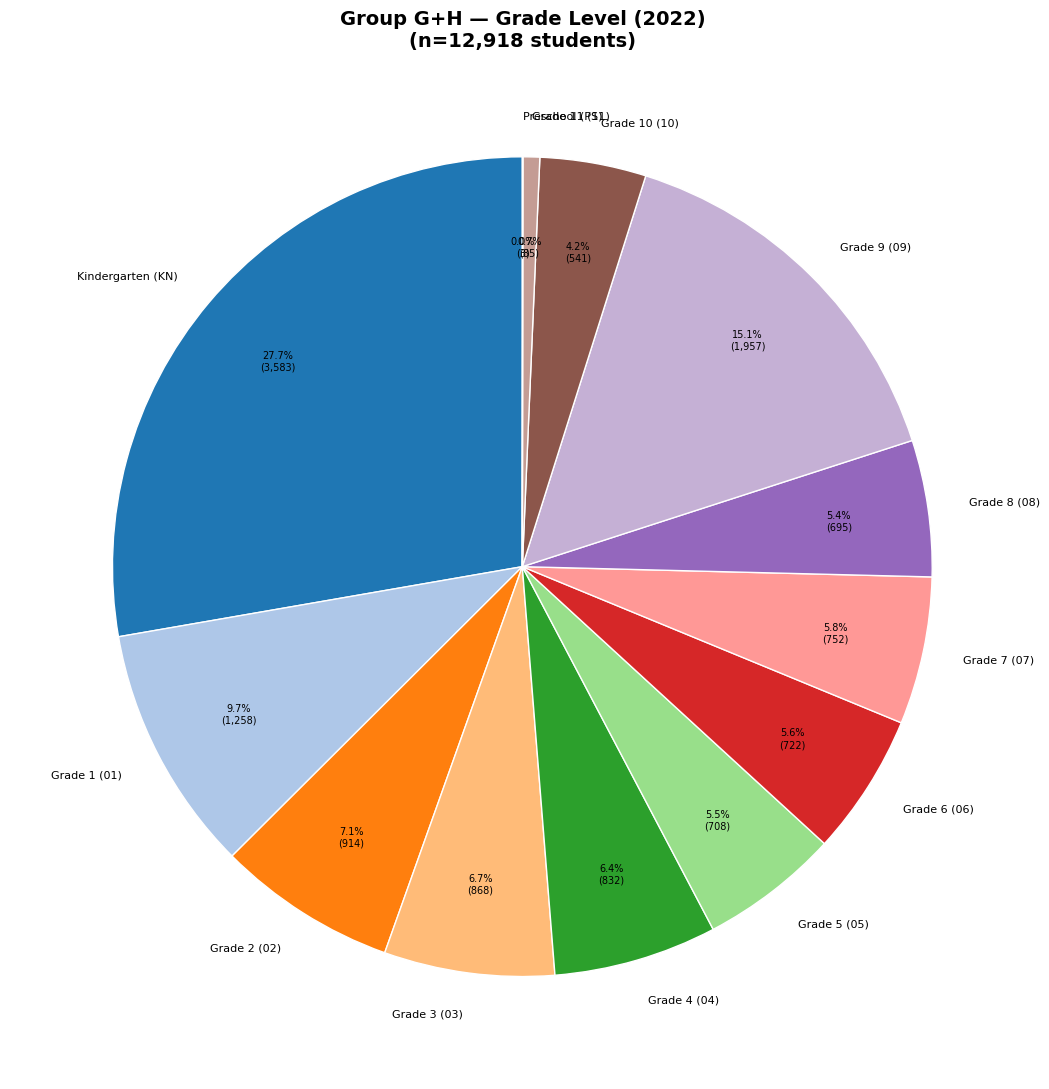

Saved: plots/group_gh_pie_grade.png

Grade Level (2022) — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
Kindergarten (KN)                        3,583     27.7%
Grade 1 (01)                             1,258      9.7%
Grade 2 (02)                               914      7.1%
Grade 3 (03)                               868      6.7%
Grade 4 (04)                               832      6.4%
Grade 5 (05)                               708      5.5%
Grade 6 (06)                               722      5.6%
Grade 7 (07)                               752      5.8%
Grade 8 (08)                               695      5.4%
Grade 9 (09)                             1,957     15.1%
Grade 10 (10)                              541      4.2%
Grade 11 (11)                               85      0.7%
Preschool (PS)                               3      0.0%
--------------------------------------------------------
Total           

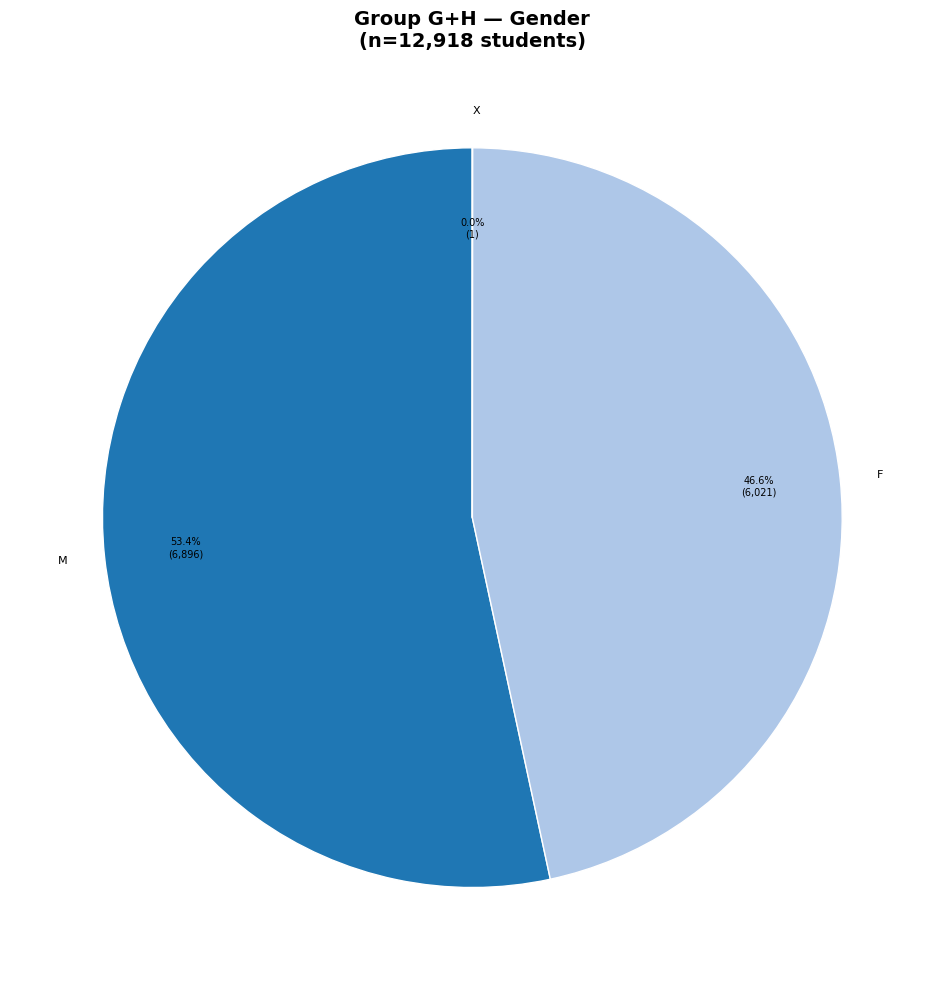

Saved: plots/group_gh_pie_gender.png

Gender — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
M                                        6,896     53.4%
F                                        6,021     46.6%
X                                            1      0.0%
--------------------------------------------------------
Total                                   12,918    100.0%



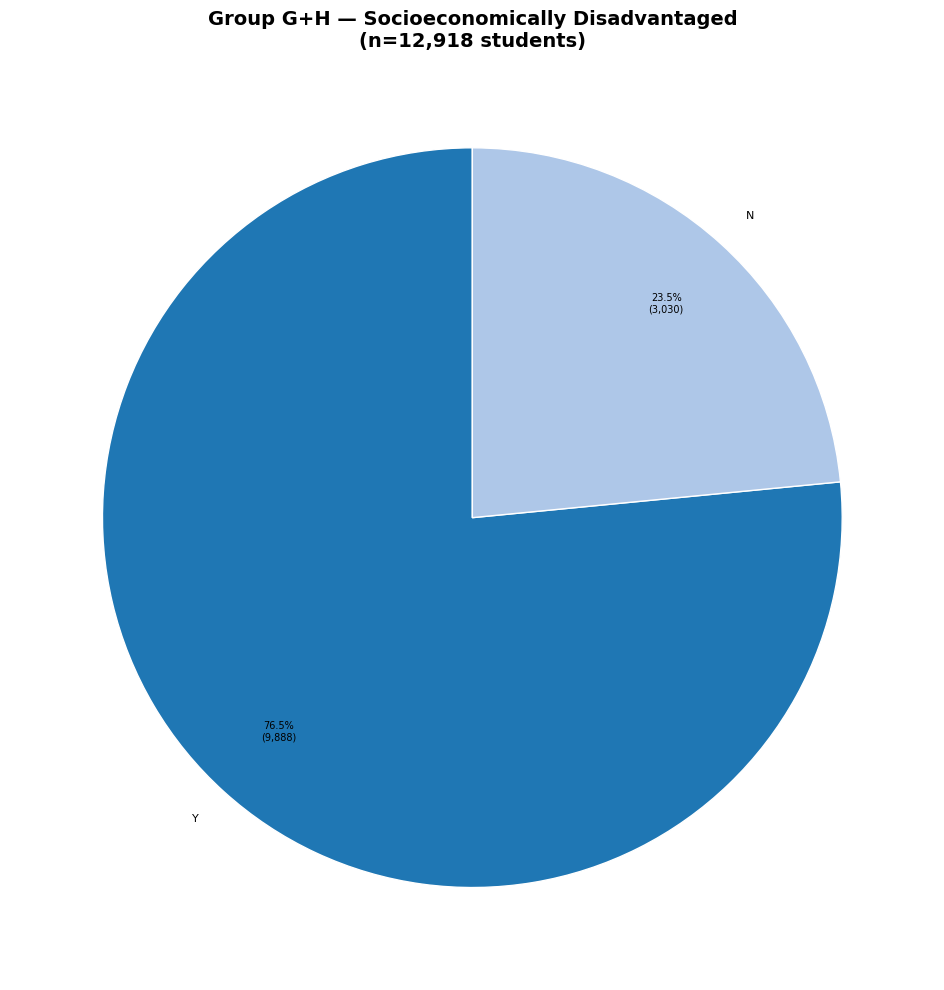

Saved: plots/group_gh_pie_sed.png

Socioeconomically Disadvantaged — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
Y                                        9,888     76.5%
N                                        3,030     23.5%
--------------------------------------------------------
Total                                   12,918    100.0%



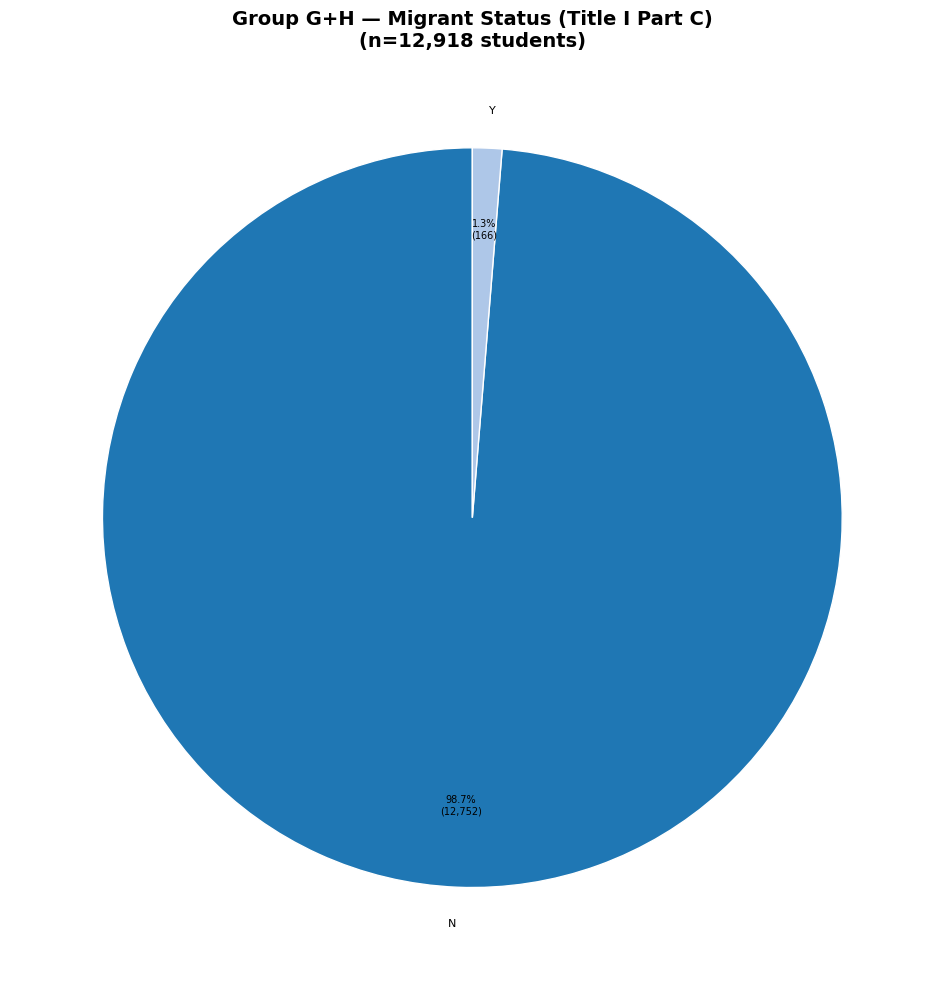

Saved: plots/group_gh_pie_migrant.png

Migrant Status (Title I Part C) — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
N                                       12,752     98.7%
Y                                          166      1.3%
--------------------------------------------------------
Total                                   12,918    100.0%



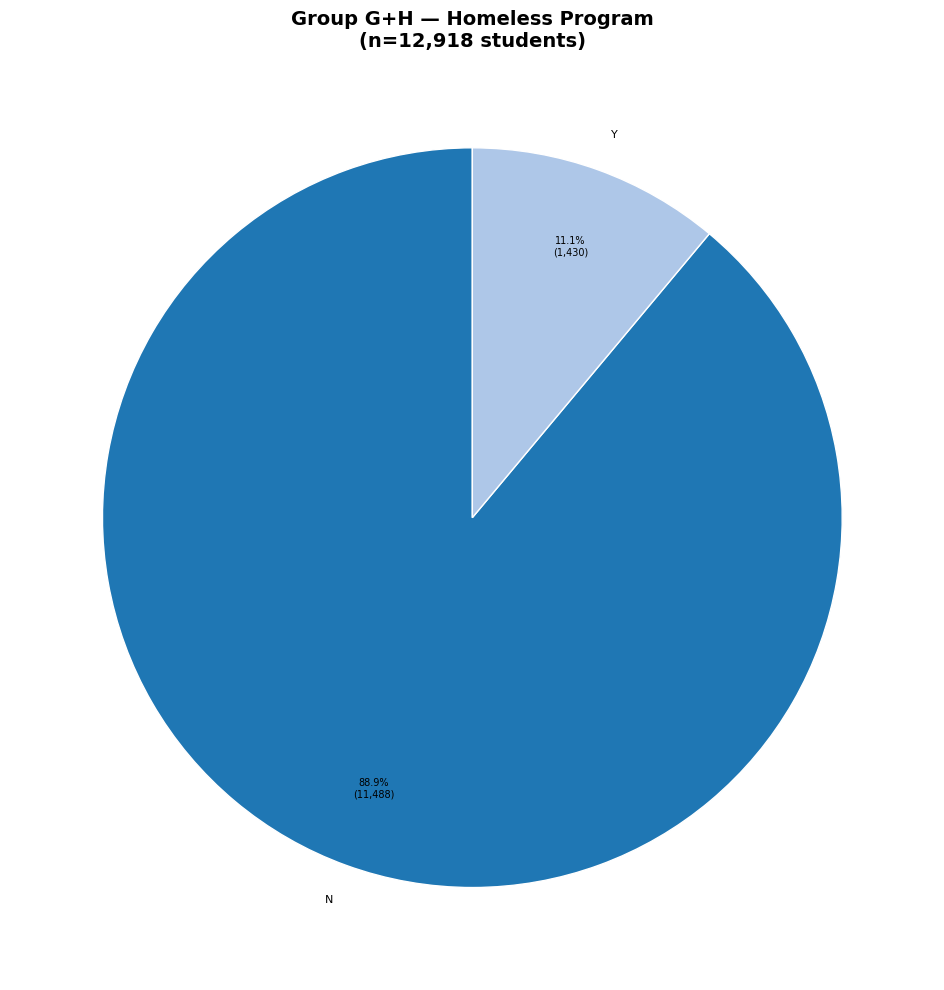

Saved: plots/group_gh_pie_homeless.png

Homeless Program — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
N                                       11,488     88.9%
Y                                        1,430     11.1%
--------------------------------------------------------
Total                                   12,918    100.0%



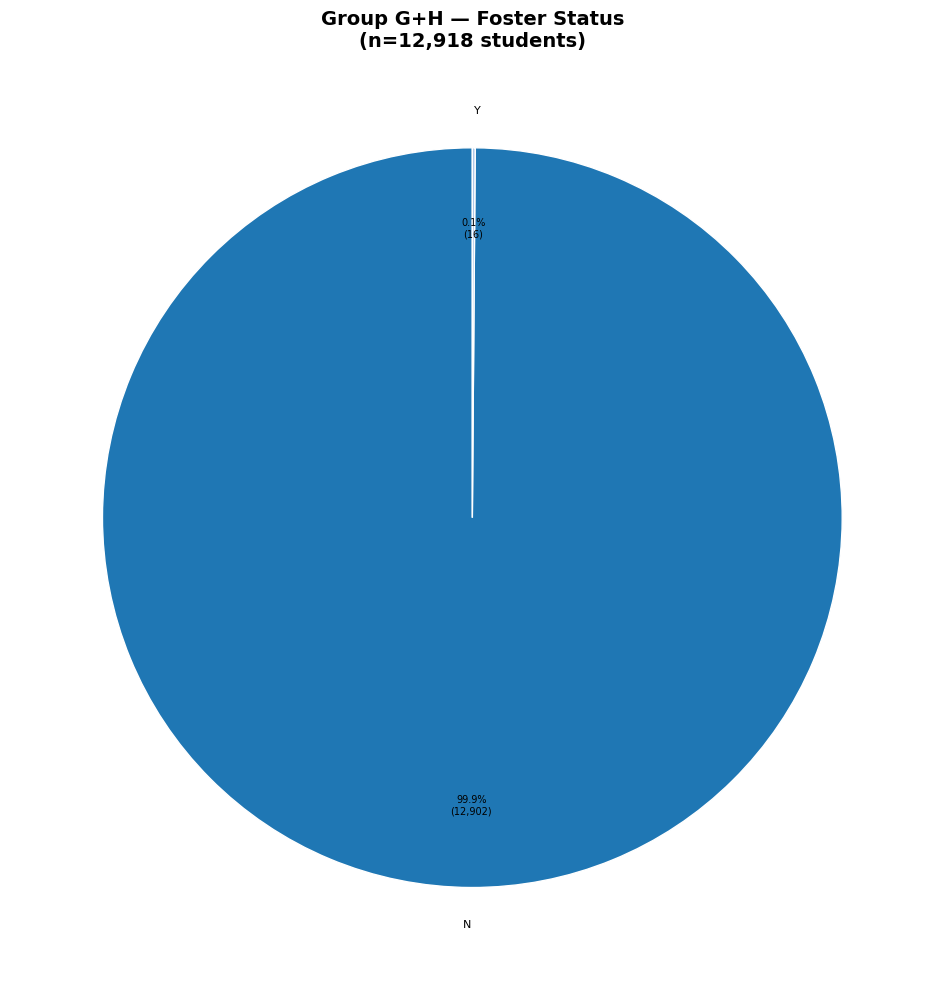

Saved: plots/group_gh_pie_foster.png

Foster Status — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
N                                       12,902     99.9%
Y                                           16      0.1%
--------------------------------------------------------
Total                                   12,918    100.0%



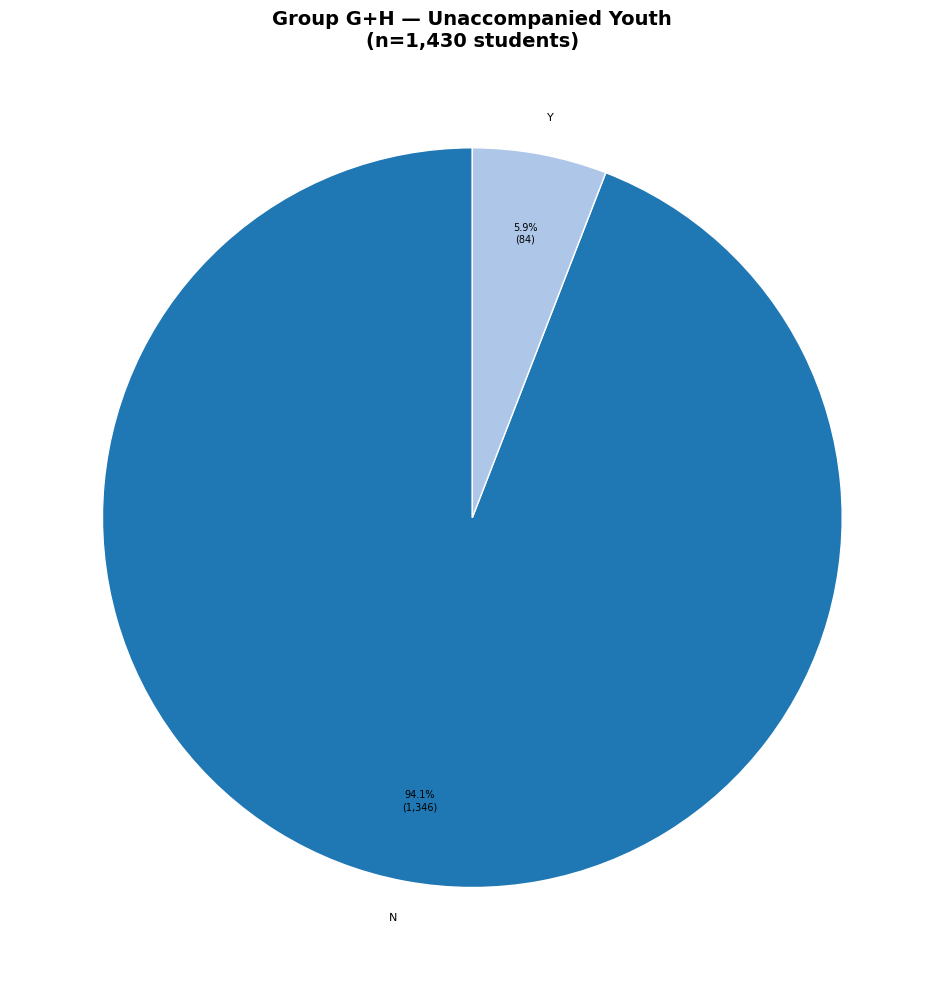

Saved: plots/group_gh_pie_youth.png

Unaccompanied Youth — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
N                                        1,346     94.1%
Y                                           84      5.9%
--------------------------------------------------------
Total                                    1,430    100.0%



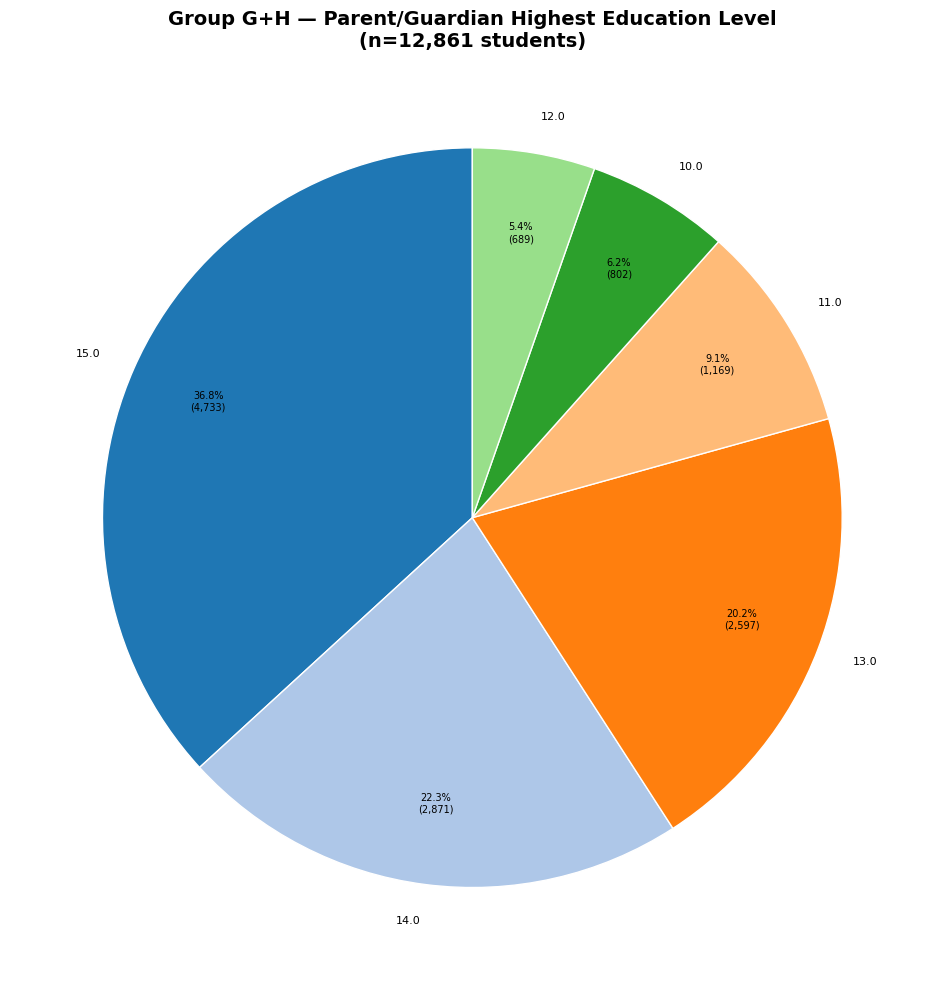

Saved: plots/group_gh_pie_edu.png

Parent/Guardian Highest Education Level — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
15.0                                     4,733     36.8%
14.0                                     2,871     22.3%
13.0                                     2,597     20.2%
11.0                                     1,169      9.1%
10.0                                       802      6.2%
12.0                                       689      5.4%
--------------------------------------------------------
Total                                   12,861    100.0%



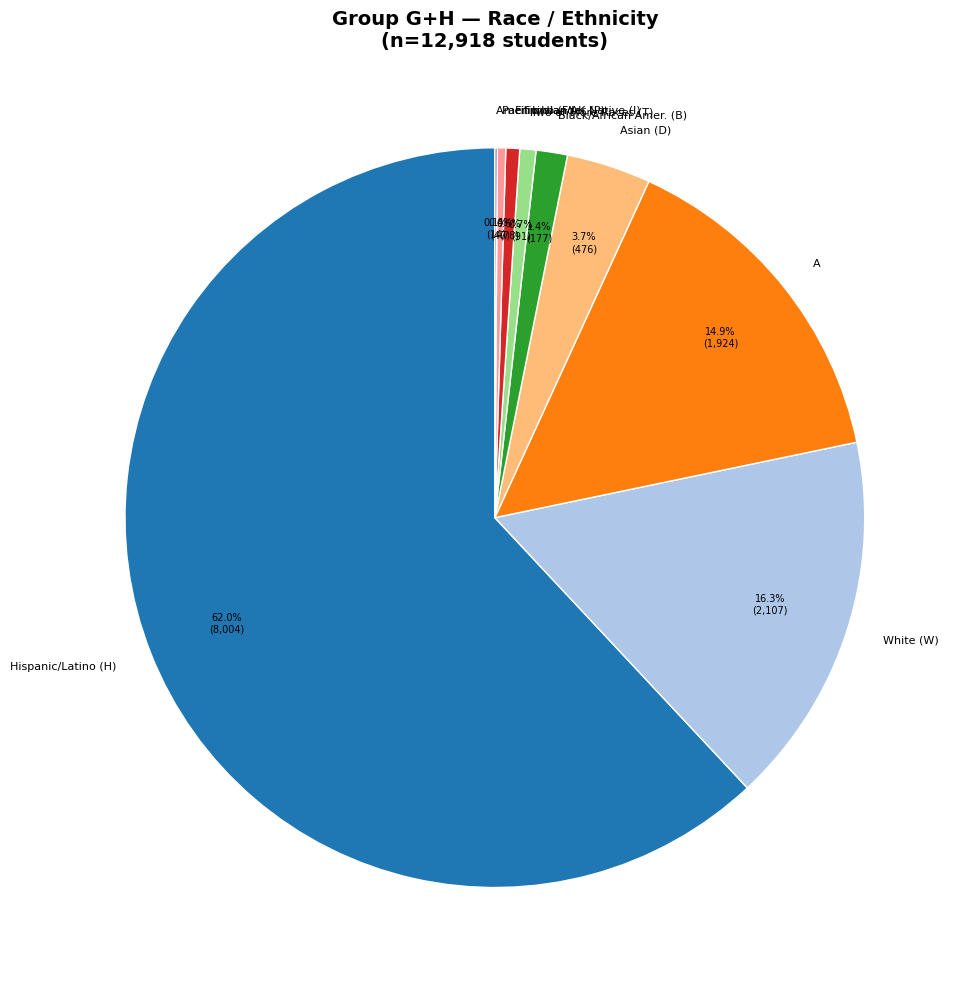

Saved: plots/group_gh_pie_race.png

Race / Ethnicity — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
Hispanic/Latino (H)                      8,004     62.0%
White (W)                                2,107     16.3%
A                                        1,924     14.9%
Asian (D)                                  476      3.7%
Black/African Amer. (B)                    177      1.4%
Two or More Races (T)                       91      0.7%
Filipino (F)                                78      0.6%
Pacific Islander (P)                        47      0.4%
Amer. Indian/AK Native (I)                  14      0.1%
--------------------------------------------------------
Total                                   12,918    100.0%



In [4]:
# --- Grade Level (natural order) ---
make_pie_and_table(
    enrollment_group["GradeLevelCode"], "Grade Level (2022)", "grade",
    label_map=grade_labels, keep_order=grade_order
)

# --- Gender ---
make_pie_and_table(
    enrollment_group["StudentGenderCode"], "Gender", "gender"
)

# --- Socioeconomically Disadvantaged ---
make_pie_and_table(
    enrollment_group["SocioeconomicallyDisadvantaged"], "Socioeconomically Disadvantaged", "sed"
)

# --- Migrant Status ---
make_pie_and_table(
    enrollment_group["TitleIPartCMigrant"], "Migrant Status (Title I Part C)", "migrant"
)

# --- Homeless ---
make_pie_and_table(
    enrollment_group["HomelessProgram"], "Homeless Program", "homeless"
)

# --- Foster ---
make_pie_and_table(
    enrollment_group["Foster"], "Foster Status", "foster"
)

# --- Unaccompanied Youth ---
make_pie_and_table(
    enrollment_group["UnaccompaniedYouthIndicator"], "Unaccompanied Youth", "youth"
)

# --- Parent Education Level ---
make_pie_and_table(
    enrollment_group["ParentGuardianHighestEducationLevelCode"],
    "Parent/Guardian Highest Education Level", "edu"
)

# --- Race / Ethnicity ---
make_pie_and_table(
    enrollment_group["RaceEthnicity"], "Race / Ethnicity", "race",
    label_map=race_labels
)

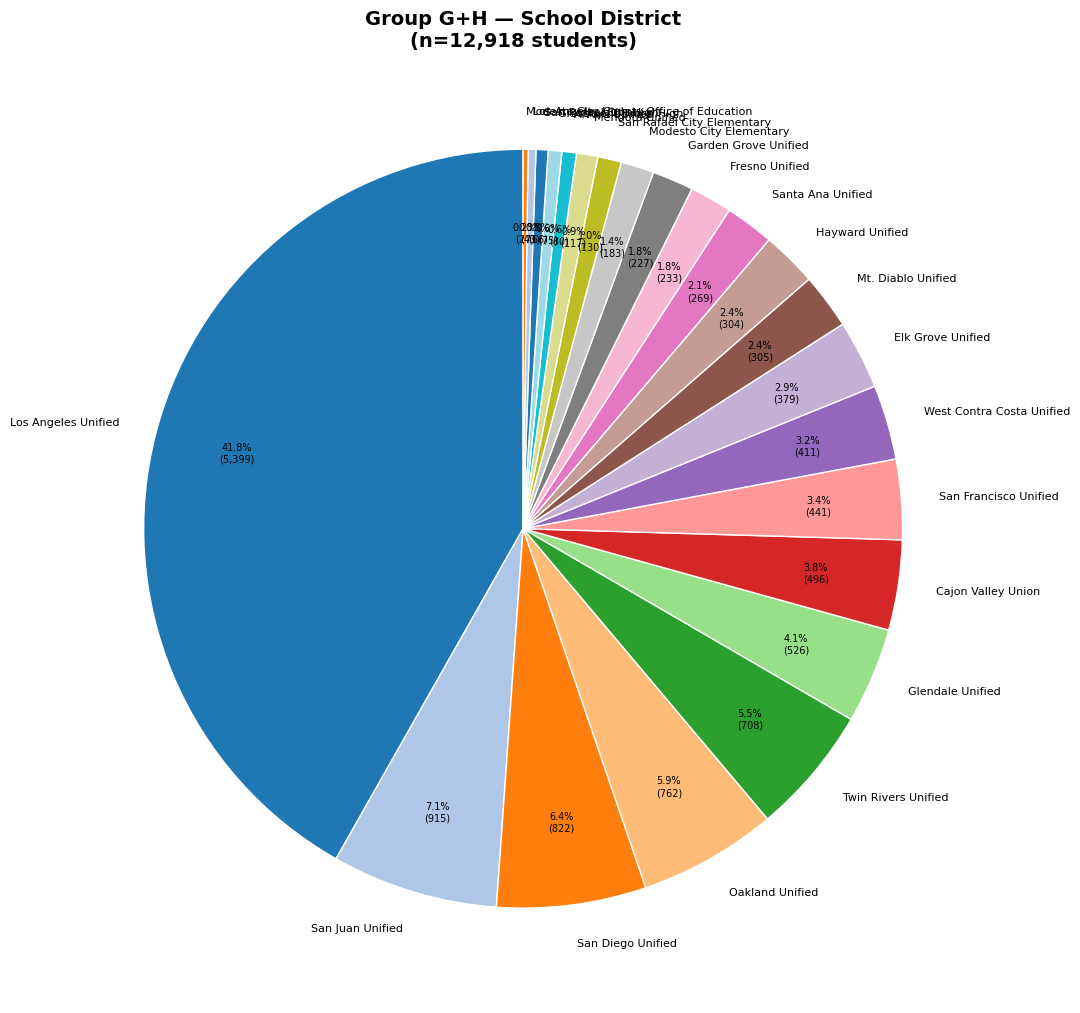

Saved: plots/group_gh_pie_district.png

School District — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
Los Angeles Unified                      5,399     41.8%
San Juan Unified                           915      7.1%
San Diego Unified                          822      6.4%
Oakland Unified                            762      5.9%
Twin Rivers Unified                        708      5.5%
Glendale Unified                           526      4.1%
Cajon Valley Union                         496      3.8%
San Francisco Unified                      441      3.4%
West Contra Costa Unified                  411      3.2%
Elk Grove Unified                          379      2.9%
Mt. Diablo Unified                         305      2.4%
Hayward Unified                            304      2.4%
Santa Ana Unified                          269      2.1%
Fresno Unified                             233      1.8%
Garden Grove Uni

In [5]:
# --- District (all districts kept) ---
make_pie_and_table(
    enrollment_group["Districtname"], "School District", "district"
)

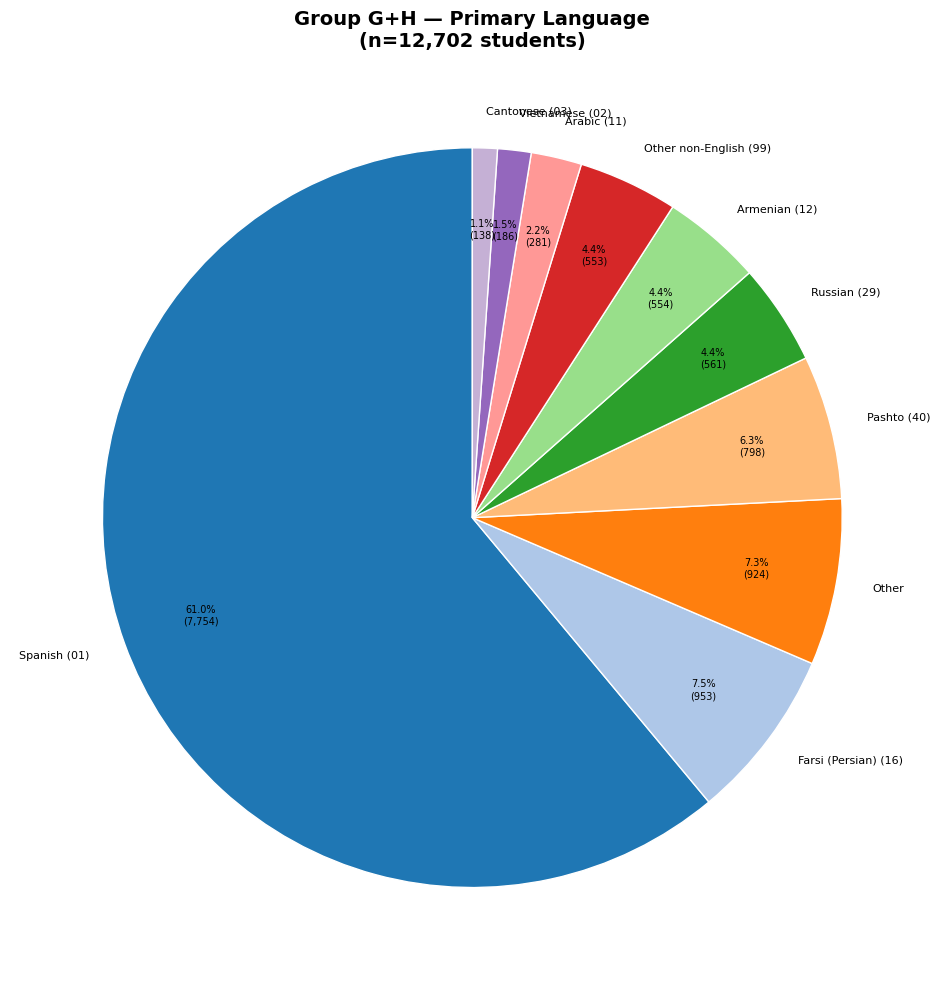

Saved: plots/group_gh_pie_language.png

Primary Language — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
Spanish (01)                             7,754     61.0%
Farsi (Persian) (16)                       953      7.5%
Other                                      924      7.3%
Pashto (40)                                798      6.3%
Russian (29)                               561      4.4%
Armenian (12)                              554      4.4%
Other non-English (99)                     553      4.4%
Arabic (11)                                281      2.2%
Vietnamese (02)                            186      1.5%
Cantonese (03)                             138      1.1%
--------------------------------------------------------
Total                                   12,702    100.0%



In [6]:
# --- Primary Language (top languages, small ones grouped as "Other") ---
make_pie_and_table(
    enrollment_group["PrimaryLanguageCode"], "Primary Language", "language",
    label_map=language_code_map, min_pct=0.01   # languages under 1% grouped into "Other"
)

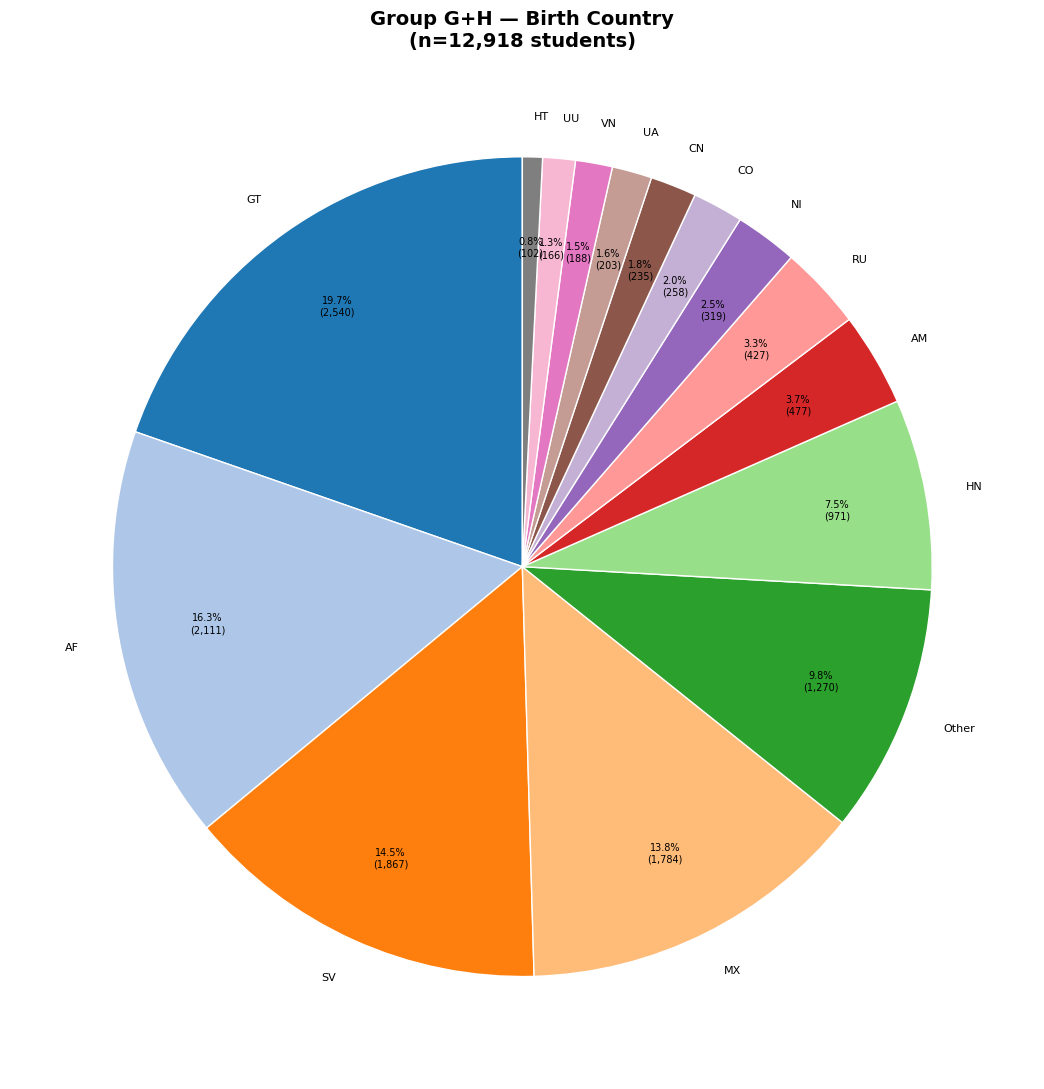

Saved: plots/group_gh_pie_country.png

Birth Country — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
GT                                       2,540     19.7%
AF                                       2,111     16.3%
SV                                       1,867     14.5%
MX                                       1,784     13.8%
Other                                    1,270      9.8%
HN                                         971      7.5%
AM                                         477      3.7%
RU                                         427      3.3%
NI                                         319      2.5%
CO                                         258      2.0%
CN                                         235      1.8%
UA                                         203      1.6%
VN                                         188      1.5%
UU                                         166      1.3%
HT                 

In [7]:
# --- Birth Country (countries with >= 100 students individually, rest as "Other") ---
# Use a count threshold rather than a percentage for consistency with earlier analysis
country_counts = enrollment_group["StudentBirthCountryCode"].dropna().astype(str).str.strip().value_counts()
min_students = 100
total_country = country_counts.sum()
# Convert the 100-student threshold into a fraction for the helper
min_pct_country = min_students / total_country

make_pie_and_table(
    enrollment_group["StudentBirthCountryCode"], "Birth Country", "country",
    min_pct=min_pct_country
)

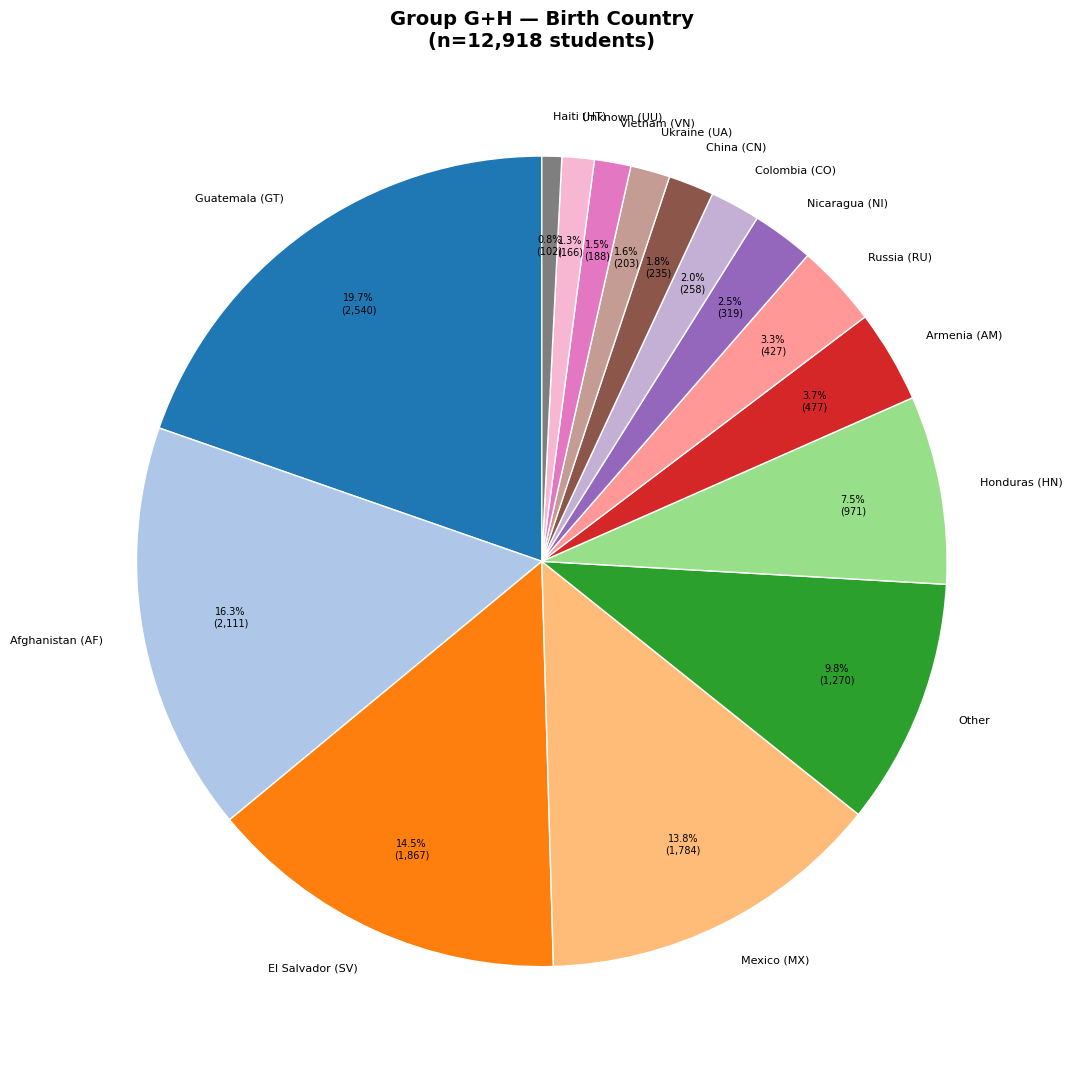

Saved: plots/group_gh_pie_country.png

Birth Country — Distribution:
Category                                 Count   Percent
--------------------------------------------------------
Guatemala (GT)                           2,540     19.7%
Afghanistan (AF)                         2,111     16.3%
El Salvador (SV)                         1,867     14.5%
Mexico (MX)                              1,784     13.8%
Other                                    1,270      9.8%
Honduras (HN)                              971      7.5%
Armenia (AM)                               477      3.7%
Russia (RU)                                427      3.3%
Nicaragua (NI)                             319      2.5%
Colombia (CO)                              258      2.0%
China (CN)                                 235      1.8%
Ukraine (UA)                               203      1.6%
Vietnam (VN)                               188      1.5%
Unknown (UU)                               166      1.3%
Haiti (HT)         

In [8]:
# --- Birth Country code-to-name lookup (ISO 3166-1 alpha-2, common CALPADS values) ---
country_code_map = {
    "US": "United States", "MX": "Mexico", "GT": "Guatemala", "SV": "El Salvador",
    "HN": "Honduras", "NI": "Nicaragua", "CR": "Costa Rica", "PA": "Panama",
    "BZ": "Belize", "CU": "Cuba", "DO": "Dominican Republic", "HT": "Haiti",
    "PR": "Puerto Rico", "CO": "Colombia", "VE": "Venezuela", "PE": "Peru",
    "EC": "Ecuador", "BR": "Brazil", "AR": "Argentina", "CL": "Chile",
    "BO": "Bolivia", "PY": "Paraguay", "UY": "Uruguay",
    "CN": "China", "KR": "South Korea", "KP": "North Korea", "JP": "Japan",
    "TW": "Taiwan", "HK": "Hong Kong", "MN": "Mongolia",
    "PH": "Philippines", "VN": "Vietnam", "KH": "Cambodia", "TH": "Thailand",
    "MM": "Myanmar", "LA": "Laos", "ID": "Indonesia", "MY": "Malaysia",
    "IN": "India", "PK": "Pakistan", "BD": "Bangladesh", "LK": "Sri Lanka",
    "NP": "Nepal", "AF": "Afghanistan",
    "UZ": "Uzbekistan", "KZ": "Kazakhstan", "KG": "Kyrgyzstan", "TJ": "Tajikistan",
    "TM": "Turkmenistan", "AZ": "Azerbaijan", "AM": "Armenia", "GE": "Georgia",
    "RU": "Russia", "UA": "Ukraine", "BY": "Belarus", "MD": "Moldova",
    "PL": "Poland", "AL": "Albania", "LV": "Latvia", "EE": "Estonia",
    "LT": "Lithuania",
    "IQ": "Iraq", "SY": "Syria", "YE": "Yemen", "JO": "Jordan", "LB": "Lebanon",
    "EG": "Egypt", "MA": "Morocco", "DZ": "Algeria", "SA": "Saudi Arabia",
    "IR": "Iran", "PS": "Palestine", "KW": "Kuwait", "QA": "Qatar",
    "AE": "U. Arab Emirates", "DJ": "Djibouti", "IL": "Israel", "TR": "Turkey",
    "ET": "Ethiopia", "SD": "Sudan", "ER": "Eritrea", "KE": "Kenya",
    "UG": "Uganda", "RW": "Rwanda", "TZ": "Tanzania", "ZA": "South Africa",
    "ZM": "Zambia", "CD": "DR Congo", "CG": "Congo", "CM": "Cameroon",
    "AO": "Angola", "CF": "Central African Rep.", "CI": "Côte d'Ivoire",
    "SL": "Sierra Leone", "MR": "Mauritania", "NG": "Nigeria", "GH": "Ghana",
    "SO": "Somalia",
    "FR": "France", "DE": "Germany", "IT": "Italy", "GB": "United Kingdom",
    "ES": "Spain", "NL": "Netherlands", "CH": "Switzerland", "BE": "Belgium",
    "SE": "Sweden", "NO": "Norway", "MC": "Monaco", "CA": "Canada",
    "FJ": "Fiji", "AS": "American Samoa", "MH": "Marshall Islands", "PG": "Papua New Guinea",
    "UU": "Unknown", "UM": "U.S. Minor Outlying",
}

# --- Birth Country (countries with >= 100 students individually, rest as "Other") ---
country_counts = enrollment_group["StudentBirthCountryCode"].dropna().astype(str).str.strip().value_counts()
min_students = 100
total_country = country_counts.sum()
min_pct_country = min_students / total_country

make_pie_and_table(
    enrollment_group["StudentBirthCountryCode"], "Birth Country", "country",
    label_map=country_code_map, min_pct=min_pct_country
)